# The observed Local Group and interpretation

No consensus mass is given in this section because of the simulation dependence of the posteriors.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

The observed input uses r=765±15 kpc, physical vr=-109.3±4.4 km/s, vt=82.4±31.2
km/s, MW stellar mass 6.08±1.14×10^10 and M31 stellar mass 10.3(-1.7,+2.3)×10^10
solar masses. Positive variables use positive distributions; M31 uses an asymmetric
positive log-space approximation. Component stellar masses are drawn in linear units,
summed, then logged. The observation table gives the references and assumptions.

Convert vr,pec=vr,phys-H0×r/1000 before feature scaling. H0=68.1 for FLAMINGO
and the combined reference, and 67.74 for TNG. The resulting nominal peculiar values
are -161.3965 and -161.1211 km/s.

The nominal posteriors use 100000 draws. Approximate uncertainty propagation averages
20 conditional draws for each of 5000 independent observational realizations. This
observational-input mixture is not exact likelihood-based marginalization. Its inputs
are assumed independent. Observed disc/bulge or aperture stellar masses differ from
the all-bound simulation catalogue definition.


flamingo nominal peculiar vr: -161.3965 km/s
tng nominal peculiar vr: -161.1211 km/s
combined nominal peculiar vr: -161.3965 km/s


,model,inference_type,posterior_draws,observational_mc_count,log_median,mass_q16_msun,mass_median_msun,mass_q84_msun
0,flamingo_dynamics,nominal,100000,1,12.471439,1.935816e+12,2.961007e+12,4.547617e+12
1,flamingo_dynamics,observational_uncertainty,100000,5000,12.478419,1.954783e+12,3.008980e+12,4.686953e+12
2,flamingo_stellar_sum,nominal,100000,1,12.475094,2.193202e+12,2.986031e+12,4.070145e+12
3,flamingo_stellar_sum,observational_uncertainty,100000,5000,12.478620,2.179514e+12,3.010371e+12,4.150181e+12
4,tng_dynamics,nominal,100000,1,12.508712,1.909936e+12,3.226356e+12,5.434230e+12
5,tng_dynamics,observational_uncertainty,100000,5000,12.515512,1.927408e+12,3.277265e+12,5.612861e+12
6,tng_stellar_sum,nominal,100000,1,12.749084,4.364854e+12,5.611565e+12,7.200849e+12
7,tng_stellar_sum,observational_uncertainty,100000,5000,12.755970,4.166889e+12,5.701249e+12,7.917311e+12
8,combined_dynamics,nominal,100000,1,12.506304,1.931259e+12,3.208516e+12,5.362506e+12
9,combined_dynamics,observational_uncertainty,100000,5000,12.508722,1.970463e+12,3.226427e+12,5.415886e+12


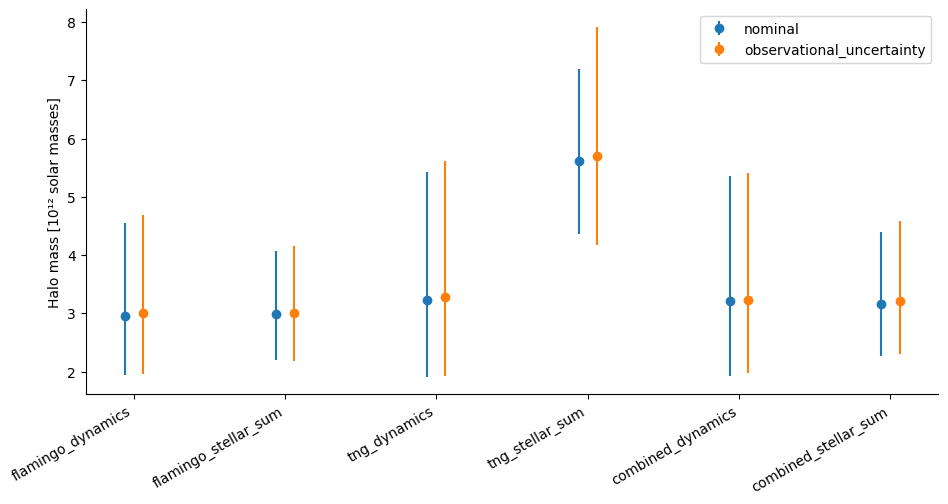

,inference_type,contrast,reference_model,comparison_model,median_difference_dex,width68_difference_dex,width68_percentage_change,width95_difference_dex
0,nominal,add_stellar,flamingo_dynamics,flamingo_stellar_sum,0.003655,-0.102388,-27.603930,-0.207300
1,nominal,add_stellar,tng_dynamics,tng_stellar_sum,0.240372,-0.236705,-52.124022,-0.470605
2,nominal,add_stellar,combined_dynamics,combined_stellar_sum,-0.006706,-0.154668,-34.872283,-0.307214
3,nominal,TNG_minus_FLAMINGO,flamingo_dynamics,tng_dynamics,0.037273,0.083200,22.430616,0.166386
4,nominal,combined_minus_FLAMINGO,flamingo_dynamics,combined_dynamics,0.034865,0.072608,19.575000,0.143546
5,nominal,combined_minus_TNG,tng_dynamics,combined_dynamics,-0.002408,-0.010592,-2.332436,-0.022840
6,nominal,TNG_minus_FLAMINGO,flamingo_stellar_sum,tng_stellar_sum,0.273990,-0.051117,-19.035862,-0.096919
7,nominal,combined_minus_FLAMINGO,flamingo_stellar_sum,combined_stellar_sum,0.024504,0.020328,7.570020,0.043633
8,nominal,combined_minus_TNG,tng_stellar_sum,combined_stellar_sum,-0.249486,0.071445,32.861317,0.140552
9,observational_uncertainty,add_stellar,flamingo_dynamics,flamingo_stellar_sum,0.000201,-0.100085,-26.352491,-0.200459


In [2]:
for source,h0 in [('flamingo',68.1),('tng',67.74),('combined',68.1)]:
    print(source,'nominal peculiar vr:',-109.3-h0*765/1000,'km/s')
lg=table('local_group/local_group_posterior_summary.csv')
display(lg[['model','inference_type','posterior_draws','observational_mc_count','log_median',
            'mass_q16_msun','mass_median_msun','mass_q84_msun']])
fig,ax=plt.subplots(figsize=(11,5))
keys=list(lg.model.unique())
for j,(kind,part) in enumerate(lg.groupby('inference_type')):
    part=part.set_index('model').loc[keys]
    med=part.mass_median_msun.to_numpy()/1e12
    lo=part.mass_q16_msun.to_numpy()/1e12; hi=part.mass_q84_msun.to_numpy()/1e12
    ax.errorbar(np.arange(len(part))+(j-.5)*.12,med,yerr=np.vstack([med-lo,hi-med]),fmt='o',label=kind)
ax.set_xticks(range(len(keys)),keys,rotation=30,ha='right');ax.set_ylabel('Halo mass [10¹² solar masses]')
ax.legend();plt.show()
display(table('local_group/local_group_model_contrasts.csv'))

### Full nominal and observational-input-mixture posteriors

The curves are histograms of the posterior draws, normalized per dex. Solid curves use
nominal inputs; dashed curves average over observational realizations. The table above
uses the saved quantiles, which are calculated from the draws rather than these bins.


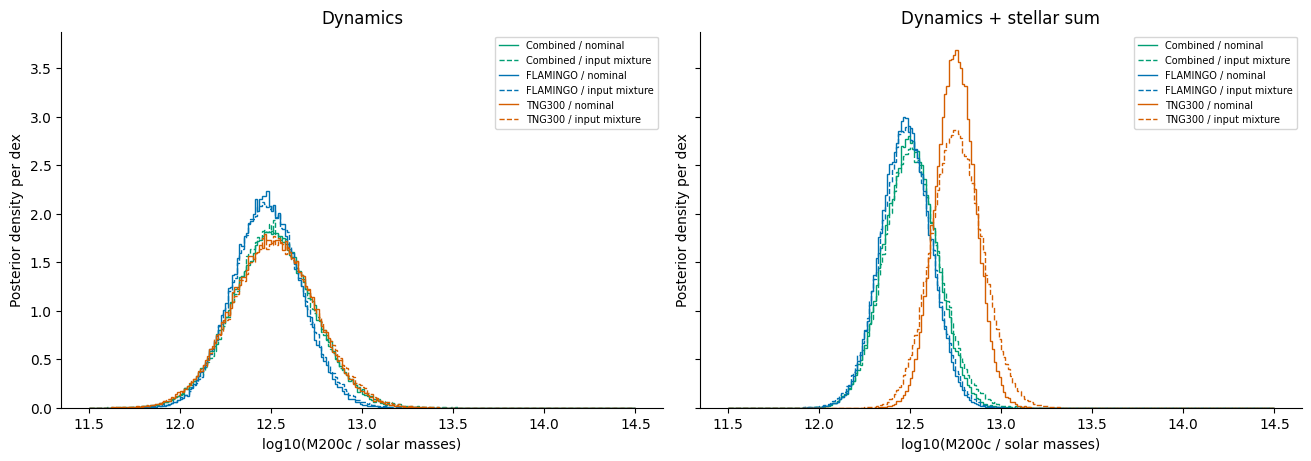

In [3]:
densities=table('local_group/posterior_histograms.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharex=True,sharey=True,layout='constrained')
colours={'flamingo':'#0072B2','tng':'#D55E00','combined':'#009E73'}
labels={'flamingo':'FLAMINGO','tng':'TNG300','combined':'Combined'}
for ax,family,title in zip(axes,['dynamics','stellar_sum'],['Dynamics','Dynamics + stellar sum']):
    for (model,kind),part in densities.groupby(['model','inference_type'],sort=False):
        if not model.endswith('_'+family):
            continue
        part=part.sort_values('lower')
        domain=model.removesuffix('_'+family)
        edges=np.r_[part.lower.to_numpy(),part.upper.iloc[-1]]
        assert np.isclose(np.sum(part.density*(part.upper-part.lower)),1,atol=1e-10)
        treatment='nominal' if kind=='nominal' else 'input mixture'
        ax.stairs(part.density,edges,color=colours[domain],
                  linestyle='-' if kind=='nominal' else '--',
                  label=labels[domain]+' / '+treatment)
    ax.set(title=title,xlabel='log10(M200c / solar masses)',ylabel='Posterior density per dex')
    ax.legend(fontsize=7)
plt.show()

The dynamics-only posteriors are wider and agree more closely. Absolute stellar mass
adds information within simulations while making the specialist disagreement much
larger. The combined stellar result lies closer to FLAMINGO at the nominal input;
this is regional and feature-dependent rather than proof of an unbalanced optimizer.

### Stellar-input sensitivity and conditional maps

Varying the assumed stellar sum is a diagnostic of input sensitivity. It does not change the adopted observations. Conditional maps show that combined-model preference
changes with separation, velocity and stellar mass. The statistic S=|C-T|-|C-F|
is positive where the combined median is closer to FLAMINGO. The support and
specialist-gap masks must be displayed when interpreting this comparison.


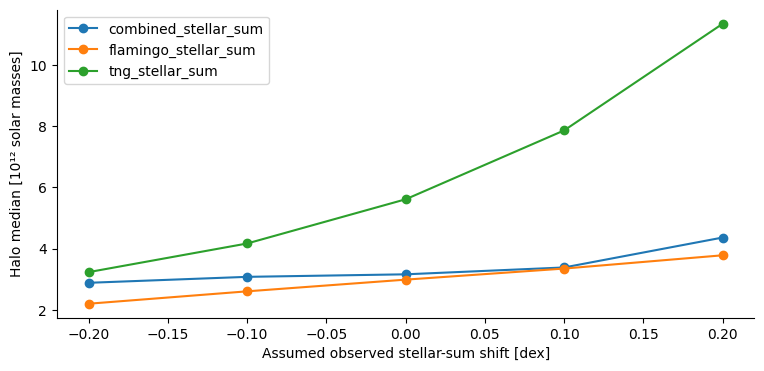

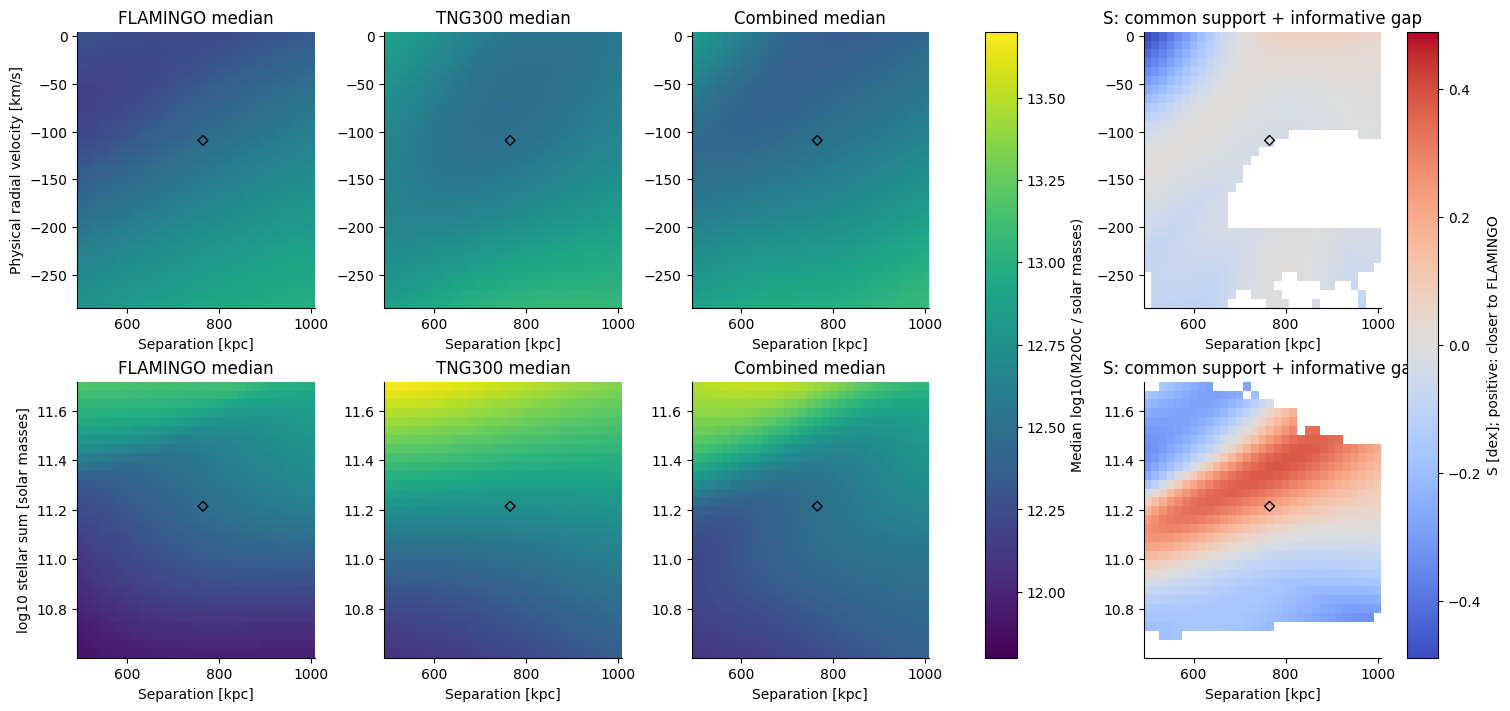

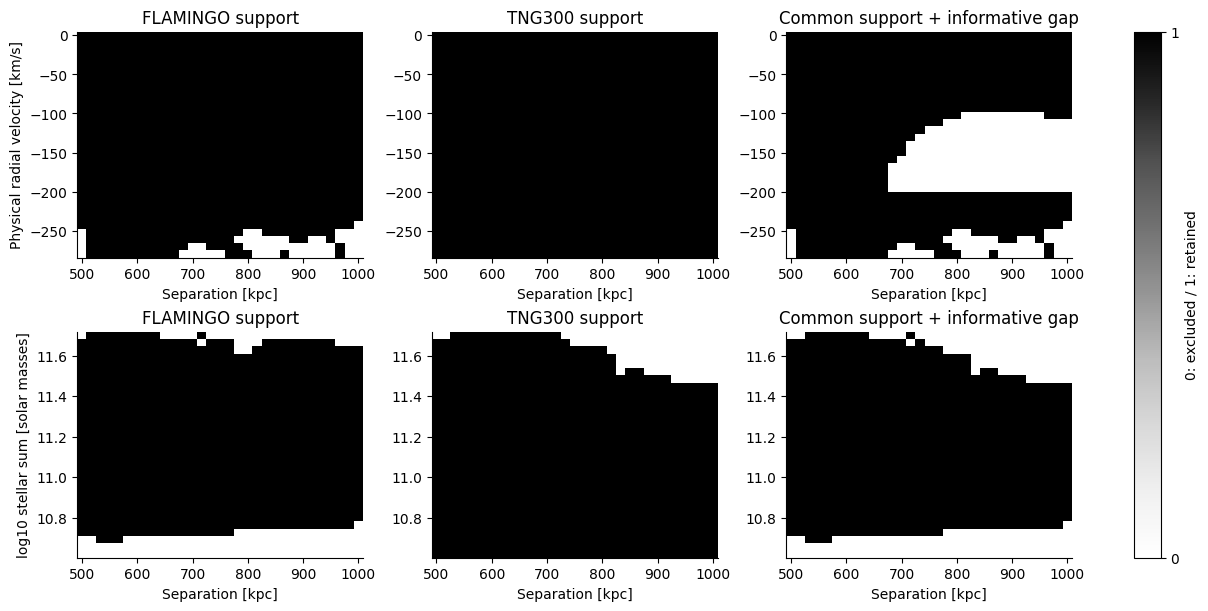

,model,feature,nominal_raw,nominal_scaled,H0,status,any_feature_outside_fraction,n_observations,...,train_q05,train_q50,train_q95,train_q99,nominal_outside,below_fraction,above_fraction,outside_fraction
0,flamingo_dynamics,separation,765.000000,0.001842,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,528.078580,773.072145,979.634733,995.919312,False,0.0000,0.0,0.0000
1,flamingo_dynamics,vr,-161.396500,-0.452577,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,-285.418301,-110.390751,-20.580969,-4.562373,False,0.0000,0.0,0.0000
2,flamingo_dynamics,vt,82.400002,-0.366824,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,18.673509,94.272634,244.900655,286.368631,False,0.0002,0.0,0.0002
3,flamingo_stellar_sum,separation,765.000000,0.001842,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,528.078580,773.072145,979.634733,995.919312,False,0.0000,0.0,0.0000
4,flamingo_stellar_sum,vr,-161.396500,-0.452577,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,-285.418301,-110.390751,-20.580969,-4.562373,False,0.0000,0.0,0.0000
5,flamingo_stellar_sum,vt,82.400002,-0.366824,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,18.673509,94.272634,244.900655,286.368631,False,0.0002,0.0,0.0002
6,flamingo_stellar_sum,log_stellar_sum,11.214314,0.108315,68.10,available: verified frozen training rows; no v...,0.0002,5000,...,10.812391,11.170400,11.620859,11.740609,False,0.0000,0.0,0.0000
7,tng_dynamics,separation,765.000000,0.123348,67.74,available: verified frozen training rows; no v...,0.0008,5000,...,520.575623,741.228638,975.160950,995.143799,False,0.0000,0.0,0.0000
8,tng_dynamics,vr,-161.121094,-0.016044,67.74,available: verified frozen training rows; no v...,0.0008,5000,...,-319.679138,-149.447357,-27.580997,-9.595573,False,0.0000,0.0,0.0000
9,tng_dynamics,vt,82.400002,-0.663762,67.74,available: verified frozen training rows; no v...,0.0008,5000,...,25.337255,124.806656,259.434143,292.012787,False,0.0008,0.0,0.0008


In [4]:
stellar=table('stellar_sensitivity/lg_stellar_mass_sensitivity.csv')
fig,ax=plt.subplots()
for model,part in stellar.groupby('model'):
    ax.plot(part.stellar_shift_dex,part.halo_median_msun/1e12,'o-',label=model)
ax.set(xlabel='Assumed observed stellar-sum shift [dex]',ylabel='Halo median [10¹² solar masses]')
ax.legend();plt.show()

grids=[table('classifier/map_dynamics_r_vr.csv'),table('classifier/map_stellar_sum_r_stellar.csv')]
median_values=np.concatenate([g[[d+'_median' for d in ['flamingo','tng','combined']]].to_numpy().ravel() for g in grids])
median_low=np.floor(median_values.min()*10)/10
median_high=np.ceil(median_values.max()*10)/10
s_max=max(.01,max(np.abs(g.S).max() for g in grids))
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for row,(g,ylabel,observed_y) in enumerate(zip(grids,
        ['Physical radial velocity [km/s]','log10 stellar sum [solar masses]'],
        [-109.3,np.log10(1.638e11)])):
    for col,(domain,label) in enumerate([('flamingo','FLAMINGO'),('tng','TNG300'),('combined','Combined')]):
        z=g.pivot(index='y',columns='x',values=domain+'_median')
        median_image=axes[row,col].pcolormesh(z.columns,z.index,z.to_numpy(),
            cmap='viridis',vmin=median_low,vmax=median_high,shading='auto')
        axes[row,col].set(title=label+' median',xlabel='Separation [kpc]')
    shown=g.assign(shown=g.S.where(g.common_support & g.informative))
    z=shown.pivot(index='y',columns='x',values='shown')
    s_image=axes[row,3].pcolormesh(z.columns,z.index,z.to_numpy(),
        cmap='coolwarm',vmin=-s_max,vmax=s_max,shading='auto')
    axes[row,3].set(title='S: common support + informative gap',xlabel='Separation [kpc]')
    axes[row,0].set_ylabel(ylabel)
    for ax in axes[row]:
        ax.scatter([765],[observed_y],marker='D',s=25,facecolors='none',edgecolors='black',linewidths=1)
fig.colorbar(median_image,ax=axes[:,:3].ravel().tolist(),label='Median log10(M200c / solar masses)')
fig.colorbar(s_image,ax=axes[:,3].ravel().tolist(),label='S [dex]; positive: closer to FLAMINGO')
plt.show()

# Explicit masks show where the closeness panel is interpretable.
fig,axes=plt.subplots(2,3,figsize=(12,6),layout='constrained')
for row,g in enumerate(grids):
    masks={'FLAMINGO support':g.supported_flamingo,
           'TNG300 support':g.supported_tng,
           'Common support + informative gap':g.common_support & g.informative}
    for ax,(label,mask) in zip(axes[row],masks.items()):
        z=g.assign(shown=mask.astype(int)).pivot(index='y',columns='x',values='shown')
        mask_image=ax.pcolormesh(z.columns,z.index,z.to_numpy(),cmap='Greys',vmin=0,vmax=1,shading='auto')
        ax.set(title=label,xlabel='Separation [kpc]')
    axes[row,0].set_ylabel('Physical radial velocity [km/s]' if row==0 else 'log10 stellar sum [solar masses]')
fig.colorbar(mask_image,ax=axes.ravel().tolist(),ticks=[0,1],label='0: excluded / 1: retained')
plt.show()
display(table('local_group/local_group_support_diagnostics.csv').head(12))

### Physical explanations and limits

Feedback, finder, resolution, cosmology and selection vary simultaneously between
the simulations. The ablations and normalization test identify sensitivities, not a
unique cause. The [physical comparison](../docs/scientific_notes.ipynb) describes
these alternatives and the discriminating experiments. Independent literature masses
also use differing halo conventions, posterior peaks versus medians and other data;
apparent agreement is not a calibration test.

Models mix common-host M200c with summed-two-host M200c without a host flag.
The real Local Group is different-host, and local TNG stellar-conditioned neighbours
can be almost entirely same-host. Pooled support therefore does not establish support
for the intended two-host inference. Only two simulators and 48 different-host TNG
test pairs limit the argument.

Finder/aperture harmonization, halo-selected parent samples, controlled FLAMINGO
variants, a third simulator, host-conditioned models, seed repeats and flexible scalar
densities remain future work. Earlier exploratory m9 browsing and dynamics density-family
tests do not settle these questions.

The [Local Group workflow](../research/notebooks/original/local_group_six_model_posteriors.ipynb),
[observation conversion](../research/src/lg_npe/observation.py), and
[observation evidence](../results/local_group/local_group_observation_evidence.json).
The next notebook examines the full classifier-weighted specialist mixture explicitly.


### Physical and numerical comparison

These simulation properties provide context for the comparison. They vary together,
so the experiments cannot isolate one physical or numerical cause of transfer failure.

| Property | FLAMINGO L1_m8 | TNG300-1 |
|---|---|---|
| Code and hydrodynamics | SWIFT; SPHENIX smoothed-particle hydrodynamics | AREPO; moving-mesh magnetohydrodynamics |
| Structure catalogue | HBT-HERONS; properties measured with SOAP | SUBFIND; group and subhalo catalogue |
| Baryon mass resolution | Initial gas particle mass 1.34 × 10⁸ solar masses | Target baryon mass 1.1 × 10⁷ solar masses |
| Dark-matter mass resolution | 7.06 × 10⁸ solar masses | 5.9 × 10⁷ solar masses |
| Collisionless softening at z=0 | 2.85 kpc | 1.48 kpc |
| Physical box side | 1,000 Mpc | 205/h Mpc = 302.63 Mpc |
| Cosmology | D3A: h=0.681, Ωm=0.306, σ8=0.807 | Planck 2015: h=0.6774, Ωm=0.3089, σ8=0.8159 |
| Calibration strategy | Low-redshift stellar mass function and group/cluster gas fractions; resolution-dependent calibration | Broad agreement with stellar mass function, stellar-to-halo relation, cosmic star formation, sizes, black-hole scaling, and halo gas fractions |
| Feedback | Kinetic stellar feedback; thermal AGN in the fiducial run | Stellar winds; thermal high-accretion and kinetic low-accretion AGN feedback |
| Stellar mass used here | All mass bound to the HBT-HERONS subhalo; no fixed aperture | All mass bound to the SUBFIND subhalo; no fixed aperture |

The observational definitions remain different from the last row. A common mass unit
does not by itself harmonize aperture or finder assignment. The original physical
comparison and primary-source links are available in
[the physical comparison](../results/physical/READ_ME.ipynb).


### Comparison with earlier Local Group mass estimates

The numbers and definitions below are transcribed from thesis Table 6.4. Masses are
in 10¹² solar masses. These studies use different selections, priors, estimators, and
observational treatments; apparent agreement is not evidence of calibration.

| Study and estimate | Mass | Definition and comparison |
|---|---:|---|
| [Sawala et al. (2023)](https://arxiv.org/abs/2210.07250), Gaussian-process inference | 3.2 (+1.2, −0.9) | Sum of the two halo M200c masses; central value close to the dynamics-only medians here |
| [Lemos et al. (2021)](https://journals.aps.org/prd/abstract/10.1103/PhysRevD.103.023009), likelihood-free inference | 4.6 (+2.3, −1.8) | Sum of the two halo M200c masses; the reported central value is the posterior **peak**, not its median |
| [van der Marel et al. (2012)](https://arxiv.org/abs/1205.6864), timing argument with cosmic bias and scatter | 4.14 ± 1.36 | Sum of the two halo M200c masses |
| [van der Marel et al. (2012)](https://arxiv.org/abs/1205.6864), combined dynamical constraints | 3.17 ± 0.57 | Sum of the two **virial** masses; requires a consistent conversion for quantitative comparison with M200c |

Our target mixes a single common-host mass with summed different-host masses, without
host-class conditioning. It does not exactly match an exclusively two-halo target.
Neither the literature values nor a combined training population select a uniquely
correct simulator or justify a consensus Local Group mass.


### Discriminating experiments that remain future work

The following experiments would help distinguish the explanations that remain open.

| Experiment | Question | Main caveat |
|---|---|---|
| Common finder and common stellar measurements | Does the offset shrink when membership, aperture, centring, and weighting agree? | Requires suitable snapshots or particle catalogues; a common host M200c does not harmonize galaxy membership |
| Controlled FLAMINGO feedback/calibration variants | Do stellar relations and transfer respond within one code and cosmology? | Main variants are at m9; several calibrated parameters can change together |
| Resolution comparison within each suite | Are the stellar relation and transfer diagnostics stable with resolution? | FLAMINGO recalibrates across resolutions; lower-resolution agreement is not proof of convergence |
| Halo-mass-based eligibility from parent catalogues | How does the fixed stellar window change selection at fixed halo mass? | Objects excluded from stellar-selected caches must be recovered from the parent catalogue |
| Independent galaxy–halo observational comparisons | Which conditional relations agree with external abundance-matching or direct constraints? | Match halo definition, aperture, IMF, and central/satellite selection; account for reuse of calibration data |
| A third simulation | Does the disagreement pattern generalize, and does pooling improve transfer beyond the training domains? | Needs another feature pipeline; two-domain agreement cannot answer this |
| Flexible final-model density estimators | Does the conditional-Gaussian restriction matter for calibration and shape? | Needs final-feature and combined-model refits; the earlier dynamics comparison does not settle it |


[Previous](11_prior_and_support_sensitivity.ipynb) · [Next](13_classifier_mixture_posteriors.ipynb) · [Repository map](../README.md)
